# RFDiffusion Notebook with Cluster

Follow this tutorial to use RFDiffusion on your HPC. In this tutorial, you will learn how to edit your .sh files to run RFDiffusion with some different input PDBs.





# **<font color='#569098' size=20> RFdiffusion: Designing Protein Backbones </font>**

Tutorial from Meiler Lab and Miranda Simpson
Additional Reading:
* RFdiffusion paper,
* RFDiffusion-AA,
* RFD3


---

### **OBJECTIVES**

By the end of this notebook you should be able to:

* <font color='#e59454'>Explain what RFdiffusion is and why it is used</font>
* <font color='#e59454'>Describe the inputs required for an RFdiffusion run</font>
* <font color='#e59454'>Understand the output files generated</font>
* <font color='#e59454'>Run RFdiffusion on the cluster</font>
* <font color='#e59454'>Interpret the generated protein backbones</font>

### **TUTORIAL**
The tutorial will allow you to run RFDiffusion to test:
* <font color='#e59454'>Unconditional monomer generation</font>
* <font color='#e59454'>Binder generation</font>
* <font color='#e59454'>Motif scaffolding</font>



---

**_Please save a copy of this notebook to your own Google Drive before beginning._**

# <font color='#569098'>What is RFdiffusion?</font>

> RFDiffusion is a backbone generation tool that utilizes a denoising diffusion probabalistic model (DDPM) to generate protein backbones. Proteins fold into stable three-dimensional structures because of interactions between their amino acids. RFdiffusion learns these structural patterns directly from experimentally determined proteins.

> RFDiffusion was trained on structures from the Protein Data Bank (PDB)

>DDPMs iteratively add noise to training structures until the noised data resembles a Gaussian Distribution. The neural network learns to 'un-noise' this data resulting in completely new structures.

In [ ]:
from IPython.display import Image, display

display(Image(url="https://github.com/miranda13nicoles/ML_bootcamp/blob/main/images/RFD_image.jpeg?raw=true", width=800))

##Install a protein viewer

In [ ]:
!pip -q install py3Dmol

# <font color='#569098'>1. Setup</font>


### Activate into your RFDiffusion Conda Environment

Note that conda environments are case-sensitive
To check your installed environments you can run:
conda info --envs


```bash
conda activate RFDiffusion

#conda info --envs


# <font color='#569098'>1. Unconditional Monomer Generation</font>
>The first task is to use unconditional monomer generation to create a monomer that is not conditioned on anything else. This creates a de novo protein completely from scratch

>We use bash scripting to create scripts that run RFDiffusion. This first script will run an unconditional monomer generation.


In [ ]:
from IPython.display import Image, display

display(Image(url="https://github.com/miranda13nicoles/ML_bootcamp/blob/main/images/unconditional_rfd_ml.jpeg?raw=true", width=800))

##1. Create the unconditional generation script in your HPC

>In your scripts folder, you can create a script called 'unconditional_generation.sh' using vim/nano.


```bash
#!/bin/bash
#SBATCH --account=parisahlab
#SBATCH --partition=gpu
#SBATCH --constraint=gpu-80gb
#SBATCH --gpus=1
#SBATCH --job-name=test_unconditional
#SBATCH --output=.../rfd_unconditional.out
#SBATCH --error=.../rfd_unconditional.err
#SBATCH --time=00-01:00:00
#SBATCH --mail-type=BEGIN,END,FAIL
#SBATCH --mail-user=mirans@uoregon.edu

~/miniconda3/envs/rfdiffusion/bin/python /gpfs/projects/parisahlab/mirans/ml_models/RFdiffusion/scripts/run_inference.py \
    inference.output_prefix=/home/mirans/mirans/designs/RFD/RFD/outputs/ML_bootcamp/unconditional/unconditional_basename  \
    contigmap.contigs=[100-200] \
    inference.num_designs=10


#RFD Unconditional Generation Parameter Descriptions

1. Length of the protein (150aa):
>Here we want to diffuse a 150aa protein and specify it with **'contigmap.contigs=[100-200]'**. For software specific reasons the entire argument must be enclosed in ''! The contig string allows to specify a length range of the protein which should be created. In this case we want a protein which is exactly 150aa long, so we just specify the range to only be 150. If we want to generate, e.g. a random length between 100 and 150aa, we would specify that with 'contigmap.contigs=[100-150]'.

2. The location where the output should be written to: Location including a prefix for all generated models can be specified using inference.**output_prefix=path/to/output_folder/prefix**. The output folder must exists, otherwise the script will start running and only fail at the very end!

3. Number of different backbones to create: This can be done using “**inference.num_designs=5**”, which in this case would create 5 different output backbones.

##2. Submit the unconditional generation script
>In your terminal, submit your script to your HPC with:


```
sbatch unconditional_generation.sh
```



##3. View your deisgns
>Upload your output folder into the Google Colab Notebook.

###<font color='#e59454'>1. Looking at your 10 designs, what is the secondary structure compostition?</font>


*Type your answer in the cell below*

Oddly enough, it generated only one protein, but it has an even mix of alpha helices around a beta sheet core. It looks pretty compact and not unreasonable. I don't see any hot dog buns. I'll have to give to ligandMPNN to get a sequence!

# <font color='#569098'>2. Binder Design</font>
>One of the possibilities using RFDiffusion is the de novo design of a protein binder. RFdiffusion shows excellent in silico and experimental ability to design de novo binders. Because diffusion is computationally intensive, it is often a good idea to crop the protein target around the desired interface location. (we won’t do that in this tutorial, but you should keep that in mind for your own projects).

> Additionaly, the model can be provided with so called “hotspot residues”. During training, the model has learned to create an interface that includes these hotspot residues. Here we want to show a workflow to generate de novo binders to the target.

In [ ]:
from IPython.display import Image, display

display(Image(url="https://github.com/miranda13nicoles/ML_bootcamp/blob/main/images/binder_img_ml.jpeg?raw=true", width=800))

###1. Download your pdb

>Go to this link to download the PDB  (as a legacy PDB) with code: 6OIM. Then open it in PyMol to view it:
https://www.rcsb.org/structure/6OIM


###2. Clean your PDB in PyMol

>Click the 'SEQ' button in the bottom right corner to show the sequence of your structure. You will notice that there are other molecules in your PDB structure. You can click on these molecules in the sequence banner and right-click to remove them.

>This is referred to as cleaning your structure. Ensure other molecules such as the hydrogens, magnesiums, zincs, and other small molecules are deleted.

###3. Select your hotspot residues
>Typically in binder design, you already have an area on the protein you are specifically targeting. You can condition RFDiffusion on your target area by specifying specific amino acids along the chain of your protein. We refer to these amino acids to target our binder against as hotspots!

>

>**In PyMol choose 3-6 hotspots targeting an area on 6IOM that you would like your binder to design to. You can click directly on your protein or on the specific amino acid code in the sequence banner. Take note of the sequence ID number and highlight these chosen hotspots in PyMol with a different color and save an image of your chosen hotspots on 6OIM**


>For example, if you wanted to design a binder targeting the beta sheets you might choose the following residues also shown on the PyMol image:

>K6, S39, R41, L52, D54



In [ ]:
from IPython.display import Image, display

display(Image(url="https://github.com/miranda13nicoles/ML_bootcamp/blob/main/images/6iom_hs.png?raw=true", width=600))


###3. Save your PDB
In the upper left hand corner, you can save your cleaned PDB as '6OIM_cleaned.pdb'.

Go to File -> Export Structure -> export molecule -> and make sure to save as a .pdb. Upload it to your RFDiffusion inputs folder on your cluster.

###4. Create the script
####Go to your cluster and create a script named rfd_binder.sh
Remember to change paths accordingly! Ask teaching team if you need help!




```
#!/bin/bash
#SBATCH --account=parisahlab
#SBATCH --partition=gpu
#SBATCH --constraint=gpu-80gb
#SBATCH --gpus=1
#SBATCH --job-name=test_binder
#SBATCH --output=.../rfd_binder.out
#SBATCH --error=.../rfd_binder.err
#SBATCH --time=00-01:00:00
#SBATCH --mail-type=BEGIN,END,FAIL
#SBATCH --mail-user=mirans@uoregon.edu

~/miniconda3/envs/rfdiffusion/bin/python /gpfs/projects/parisahlab/mirans/ml_models/RFdiffusion/scripts/run_inference.py \
    inference.input_pdb=/home/mirans/mirans/designs/RFD/RFD/inputs/ML_bootcamp/6oim_cleaned.pdb \
    inference.deterministic=True \
    'contigmap.contigs=[A1-104/0  A108-169/0 70-150]' \
    'ppi.hotspot_res=[A6,A39,A41,A52,A54]' \
    inference.num_designs=10 \
    inference.output_prefix=/home/mirans/mirans/designs/RFD/RFD/outputs/ML_bootcamp/binder/6oim_design
```



###5. Submit your script

>Submit rfd_binder.sh using an sbatch command

###6. View and upload some of your deisgns
>View all your designs in PyMol and upload one of them in the upload button below

#RFD Binder Parameters Descriptions


##1. Specifying the input PDB

>>**inference.input_pdb=../../input_files/6iom_cleaned.pdb**

>Because we are using RFDiffusion conditioned on an input protein (6IOM) we have to state and link it via the script paramenter

##2. Fixing our input PDB

>>**“contigmap.contigs=[A1-104/0  A108-179/0 70-150]”**

>We use contigs to specify which parts of the target protein will be fixed during the diffusion process as well as the desired length of the binder. Here we want to keep the full target fixed by marking it with a preciding letter of the chain “A1-150/0” (the symbol “\0” is necessary to symbolize a chain break), followed by the binder defined by the desired range of length (1-104 and 108-179).

##3. Declaring our hotspots

>>**“ppi.hotspot_res”**

>Because we are targeting a specific area for our binder to bind to on 6IOM, we specify the hotspots that define the interface region. The hotspots are refered to as the chain ID and position of the hotspot residue in the sequence. For residues Lys6, Ser39, Arg41, Leu52, and Asp54 of chain A that means “A6,A39,A41,A52,A54”.


In [1]:
#@title 📂 Upload Your PDB

from google.colab import files
from IPython.display import HTML, display

display(HTML("""
<div style="
border-left:6px solid #569098;
background:#f8f9fa;
padding:15px;
border-radius:8px;">

<h3 style="color:#569098;">Upload Your Protein Structure</h3>

Upload the <b>.pdb</b> file generated from your design pipeline.

</div>
"""))

uploaded = files.upload()

pdb_file = next(iter(uploaded))

print(f"Uploaded: {pdb_file}")

KeyboardInterrupt: 

##Display your Design

In [1]:
# @title
import py3Dmol

with open(pdb_file, 'r') as f:
    pdb_data = f.read()

view = py3Dmol.view(width=700, height=500)
view.addModel(pdb_data, 'pdb')

# Cartoon representation
view.setStyle({'cartoon': {'color': 'spectrum'}})

view.zoomTo()
view.show()

ModuleNotFoundError: No module named 'py3Dmol'

###<font color='#e59454'>Binder Question 1.<font>

Which area of 6IOM did you target and why?

<i>Type your answer in the cell below.</i>

</div>

I targeted one of the alpha helices. Why? No reason.

###<font color='#e59454'>Binder Question 2.<font>

Which hotspot residues did you choose

<i>Type your answer in the cell below.</i>

</div>

I picked some of the residues on the alpha helice were on the surface of the protein. Binders cannot target the interior.

Saving group_meeting_sirt.png to group_meeting_sirt.png


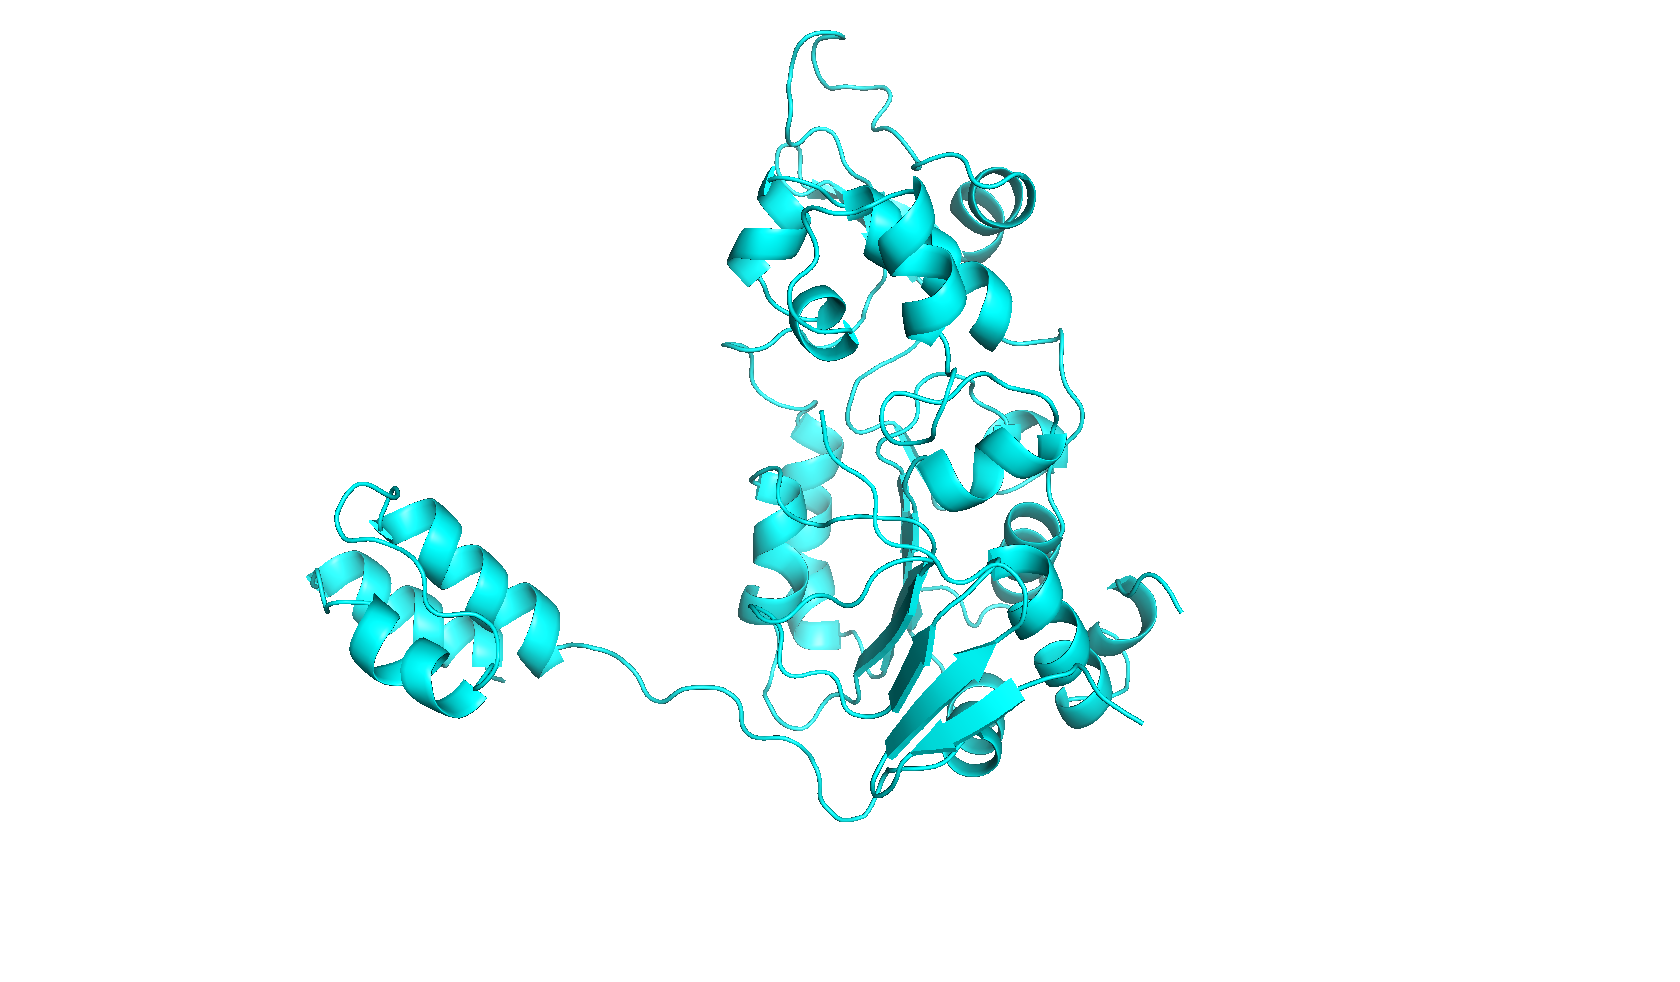

In [ ]:
#@title Upload an Image of your highlighted hotpots

from google.colab import files
from IPython.display import display, HTML
from PIL import Image

display(HTML("""
<div style="
border-left:6px solid #569098;
background:#f8f9fa;
padding:15px;
border-radius:8px;">

<h3 style="color:#569098;">Upload an Image</h3>

Upload a <b>.png</b>, <b>.jpg</b>, or <b>.jpeg</b> image.

</div>
"""))

uploaded = files.upload()

image_file = next(iter(uploaded))

img = Image.open(image_file)

display(img)

##7. Optimize your Designs
###Testing RFDiffusion Potentials for Binder Design

>We can input even more parameters in RFDiffusion to help guide our designs. These are called potentials. Understanding the different potentials to use for different use-cases can help speed up design and bias your designs into being even stronger.

>Read about more advanced RFDiffusion Potentials here:

>https://huggingface.co/blog/AmelieSchreiber/rfdiffusion-potentials

>**Try at least 3 different combinations of potentials, generating 5 backbones with each. Be sure to use hotspots for these generations too!**

# <font color='#569098'>3. Motif Scaffolding</font>


>Another use-cases for RFDiffusion is motif scaffolding. We can use RFD to generate a protein scaffold for a motif that is known to fulfill a specific purpose. To scaffold protein motifs effectively, we require:

1.  A method to specify the desired protein input (one or more segments from a .pdb file)
2.   A way to define the connections between these segments in the new scaffolded protein
3. The ability to specify the number of residues for these connections

>Additionally, we need to sample various connection lengths, as the optimal number of residues for scaffolding a motif is often not known in advance.

>

In [ ]:
from IPython.display import Image, display

display(Image(url="https://github.com/miranda13nicoles/ML_bootcamp/blob/main/images/motif_img_ml.jpeg?raw=true", width=800))

###1. Download your pdb from the Google Drive

The RFDiffusion activity folder contains the PDB 8U08.pdb and 8U08_motif.pdb.

Download both files and compare the original 8U08.pdb with the 8U08_motif.pdb that we will be using to motif graft around Chain C.


https://drive.google.com/drive/folders/1UD5HBrbY8LpjIu141TOt1GDQesmLAEUd?usp=drive_link


###<font color='#e59454'>Motif Scaffolding Question 1.<font>

What do you notice about Chain C in the original PDB and the motif PDB? How does this relate to motif scaffolding of Chain C?

<i>Type your answer in the cell below.</i>

</div>

Chain C is bound to another, extremely similar, chain. This overall dimer motif is likely what we want RFdiffusion to recreate.

###2. Upload the motif PDB to your cluster and create a rfd_motif.sh script

Remember to change paths accordingly!


```
#!/bin/bash
#SBATCH --account=parisahlab
#SBATCH --partition=gpu
#SBATCH --constraint=gpu-80gb
#SBATCH --gpus=1
#SBATCH --job-name=test_motif
#SBATCH --output=.../rfd_motif.out
#SBATCH --error=.../rfd_motif.err
#SBATCH --time=00-01:00:00
#SBATCH --mail-type=BEGIN,END,FAIL
#SBATCH --mail-user=mirans@uoregon.edu

~/miniconda3/envs/rfdiffusion/bin/python /gpfs/projects/parisahlab/mirans/ml_models/RFdiffusion/scripts/run_inference.py \
    inference.input_pdb=/home/mirans/mirans/designs/RFD/RFD/inputs/ML_bootcamp/8U08_motif.pdb \
    'contigmap.contigs=[39-39/C96-107/20-50/0 H1-131/0 L2-119/0]' \
    inference.num_designs=10 \
    inference.output_prefix=/home/mirans/mirans/designs/RFD/RFD/outputs/ML_bootcamp/motif_scaffolding/8U08_design
```



#Motif Scaffolding Parameters

>In this example we look at the interaction of membrane-proximal external region (MPER) of the HIV Envelope protein Env and antibody 10E8. We want to extract MPER and design an epitope scaffold that stabilizes MPER in the 10E8-bound conformation.

**contigmap.contigs=[39-39/C96-107/20-50/0 H1-131/0 L2-119/0]**

>The scaffold needs to be generated in a way that RFDiffusion builds exactly 39 residues (“39-39”) N-terminally of “C96-107” from the input pdb, followed by “20-50” residues to its C-terminus. All new parts are randomly sampled at each inference cyle. Also we want to inpaint the presence of the Fv fragments for the heavy and light chain of the 10E8 antibody with “H1-131/0 L2-119/0”.

###<font color='#e59454'>Motif Scaffolding Question 2.<font>

Paste your sequence before and after motif scaffolding of Chain C. Which residues stayed fixed from chain C in the sequence.

<i>Type your answer in the cell below.</i>

</div>

# <font color='#569098'>4. Understanding your output files</font>

>Since you have now explored some of the capabilities of RFDiffusion, it's helpful to understand some of your output files. There should be 3 different files that you will get as an output:



1.   .pdb files - your final designs
2.   a trajectory folder with traj.pdb files - the trajectory files at time=0 and time=1
3.   .trb files - the metadata related to your run.




##Play your trajectory files

>Trajectory files files can be opened in pymol, as multi-step pdbs. Note that these are ordered in reverse, so the first pdb is technically the last (t=1) prediction made by RFdiffusion during inference. In your outputs you get both. the pX0 predictions (what the model predicted at each timestep) and the Xt-1 trajectories (what went into the model at each timestep).


>In your outputs traj folder download a few of the trajectory pdb files and open them in PyMol.

in the PyMol command line type:

```
mplay
```
to view the diffusion process.

#<font color='#e59454'>Conceptual Questions</font>


###<font color='#e59454'>Conceptual Question 1. </font>

Explain in 2-3 sentences the role of RFDiffusion in the overall protein design pipeline

<i>Type your answer in the cell below.</i>

</div>

RFDiffusion generate de novo backbones given some (or no) constraints. This makes it essentially the first step in the computational pipeline. These structures can then be turned into sequences using ligandMPNN, and then verified with folding tools like ESMFold2. Once this is all done, you can begin testing the actual protein!

###<font color='#e59454'>Conceptual Question 2. </font>

Explain the 3 types of output files from RFDiffusion

<i>Type your answer in the cell below.</i>

</div>

A .pdb file of the final design, .pdb files of the trajectory, and a .trb metadate file.

###<font color='#e59454'>Conceptual Question 3. </font>

At which step during the diffusion process is the neural network used?

<i>Type your answer in the cell below.</i>

</div>

Denoising the initial random noise, turning it into a protein structure. Hopefully.

###<font color='#e59454'>Conceptual Question 4. </font>

In 4-5 sentences, describe 3 different use cases for RFDiffusion and specfic examples or reasons why you would use each of them.


<i>Type your answer in the cell below.</i>

</div>

###<font color='#e59454'>Conceptual Question 5. </font>

In 2-3 sentences, please describe how RFDiffusion will help you with your particular research project?

<i>Type your answer in the cell below.</i>

</div>

I want to do de novo protein design, and these models are the only way to really do that.

*Your text here*

###<font color='#e59454'>Conceptual Question 6. </font>

**Analyze and Select**

Compare your unconditional vs. hotspot-guided vs. potential-optimized designs

Identify your top 3-5 most promising binder designs


Document what makes these designs stand out (binding pose, topology, contact with hotspots, etc.)

<i>Type your answer in the cell below.</i>

</div>

# <font color='#569098'>If you finish early...</font>

##Option 1: Use RFDiffusion for your protein of interest

>If you have a specific PDB you will be working with, run RFDiffusion to create designs with your PDB. Even if your goal isn't to design a binder or to motif scaffold, creating binders and playing around with motif scaffolding can be very useful to further understand running jobs and working within the cluster.

##Option 2: Hotspot-Guided Binder Design

* Target: PD-L1 PDB Code: **5O45**
* Target: IL-7Rɑ	 PDB Code: **3DI3	**
* Target: TrkA receptor	PDB Code:**1WWW**
* Target IFNAR2	PDB Code:	**2LAG**
* Target: Bet v 1-A PDB Code:**1BV1**




###Option 3: Design binders using advanced RFDiffusion Potentials

https://huggingface.co/blog/AmelieSchreiber/rfdiffusion-potentials

>Try implementing some new potentials in your RFDiffusion scripts to bias your binders. Testing out things like Radius of Gryration, interface contacts, minimum distance, and weight can help you optimize your designs.

###Option 4: Try running symmetrical unconditional design

>Go through the RFDiffusion GitHub and design some symmetric oligimers using their examples.

###Option 5: Try motif scaffolding your protein of interest, or another PDB with multiple chains

>Try keeping the interface residues of one chain fixed while redesigning the non-interface residues using motif scaffolding.

